## 1. Załozenia projektu, dobór danych i przygotowanie środowiska

Celem projektu jest wykrycie współrzędnych punktów $(x, y)$ z obrazów wykresów oraz przeliczanie ich na rzeczywiste wartości na osi.

### Dobór zbioru danych i kryteria wyboru
Zbiór danych pobrano z oficjalnego datasetu PlotQA przy uzyciu modułu 'download_data'
* **Kryteria wyboru:** wyselekcjonowanych zostało 30 wykresów z oficjalnej kategorii 'dot_line'. znajdują się w nim wykresy jednoseryjne z czytelnymi, okrągłymi markerami oraz linowymi osiami liczbowymi. Dane są reprezentatywne pod kątem wykresów kolorowych i monochromatycznych
* **Podział zbioru:** 
    * **zbiór DEV (10 obrazów)**: słuzył do kalibracji algorytmu, detekcji markerów, oraz logiki matematycznej przeliczania wartości
    * **zbiór TEST (20 obrazów)**: zbiór testowy, nieuzywany podczas strojenia parametrów, słuzący do ostatecznej, obiektywnej weryfikacji działania całego programu

### Udział pracy ręcznej i symulacja kalibracji
Aby nie było konieczności budowania dedykowanego modułu OCR oraz zeby nie trzeba było ręcznie wskazywać obszaru wykresu, proces kalibracji zasymulowano za pomocą metadanych z pliku JSON:
1. **Kalibracja osi (`major_ticks`):** Program pobiera wartości podziałek oraz ich położenie pikselowe na obrazie (wyliczane z ramek ograniczających etykiety), wyznaczając funkcję przejścia z pikseli na wartości.
2. **Wartości referencyjne (`models`):** te wartości wykorzystywane są wyłącznie na etapie ewaluacji do obliczania miar jakościowych ($TP$, $FP$, $FN$, MAE).


In [3]:
import os
import cv2
import json
import numpy as np
import matplotlib.pyplot as plt
import sys
from scipy.optimize import linear_sum_assignment
import math
import cv2

sys.path.append(os.path.abspath(os.path.join('..', 'src')))

from detector import detect_dots
from converter import map_pixels_to_actual_values, export_to_json

ANNOTATIONS_PATH = os.path.join("..", "data", "sample_annotations.json")
IMAGES_DIR = os.path.join("..", "data", "sample_images")

with open(ANNOTATIONS_PATH, 'r', encoding='utf-8') as f:
    full_data = json.load(f)

test_ids = full_data.get("test_ids", [])
print(f"Identyfikatory zbioru testowego ({len(test_ids)}): {test_ids}")

annot_dict = {str(sample["image_index"]): sample for sample in full_data.get("samples", [])}

test_images = {}
for t_id in test_ids:
    img_path = os.path.join(IMAGES_DIR, f"{t_id}.png") 
    img_bgr = cv2.imread(img_path)
    
    if img_bgr is not None:
        test_images[t_id] = img_bgr
    else:
        print(f" [!] BŁĄD: Nie udało się wczytać obrazu testowego: {img_path}")

print(f"Pomyślnie wczytano {len(test_images)} z {len(test_ids)} obrazów zbioru TEST.")

Identyfikatory zbioru testowego (20): [4446, 4447, 4449, 4450, 4451, 4452, 4453, 4456, 4458, 4459, 4460, 4461, 4465, 4469, 4471, 4474, 4476, 4691, 4711, 4745]
Pomyślnie wczytano 20 z 20 obrazów zbioru TEST.


## 2. Generowanie predykcji dla zbioru testowego

Wykorzystujemy nasz gotowy pipeline, składający się z modułów 'detector' oraz 'converter'
Dla kazdego z 20 wykresów testowych:
1. uruchamiamy detekcję kropek
2. przeliczamy ich pozycję na wartości na osiach przy uzyciu dostarczonej kalibracji
3. wyciągamy wartości referencyjne z pliku JSON i odrzucamy punkty, które teorytycznie są w danych, ale fizycznie znajdują się poza krawędziamy wykresu


In [4]:
def get_gt_values_filtered(sample_annot):
    if "general_figure_info" not in sample_annot or "models" not in sample_annot:
        return []

    fig_info = sample_annot["general_figure_info"]
    x_ticks_vals = fig_info["x_axis"]["major_ticks"]["values"]
    x_labels_vals = fig_info["x_axis"]["major_labels"]["values"]
    index_to_label = dict(zip(x_ticks_vals, x_labels_vals))

    y_ticks_vals = [float(v) for v in fig_info["y_axis"]["major_ticks"]["values"]]
    min_y_axis = min(y_ticks_vals) if y_ticks_vals else -float("inf")

    gt_points = []
    for model in sample_annot["models"]:
        for x_idx, y_val in zip(model["x"], model["y"]):
            y_val_float = float(y_val)
            if y_val_float < min_y_axis:
                continue 
            
            actual_x = index_to_label.get(x_idx, x_idx)
            if str(actual_x).isdigit():
                actual_x = int(actual_x)
            gt_points.append({"x": actual_x, "y": round(y_val_float, 3)})

    return gt_points

test_preds = {}
test_gts = {}

for t_id in test_ids:
    sample_annot = annot_dict.get(str(t_id))
    img_bgr = test_images.get(t_id)
    
    if sample_annot and img_bgr is not None:
        fig_info = sample_annot["general_figure_info"]

        pixels = detect_dots(img_bgr)

        test_preds[t_id] = map_pixels_to_actual_values(pixels, fig_info)

        test_gts[t_id] = get_gt_values_filtered(sample_annot)

print("predykcje zostaly wygenerowane")

predykcje zostaly wygenerowane


## 3. Metodyka ewaluacji

Zgodnie z wymaganiami, jakość ekstrakcji oceniamy, przy uzyciu zbioru dedykowanych miar. Wymaga to zdefiniowania, czym jest $TP$ oraz na jakiej podstawie określamy, ze model sie pomylił

### 3.1. sposob dopasowania (hungarian algorithm)
Naszym celem jest powiązanie punktów przewidywanych ($\hat{P}$) z referencyjnymi ($P$) relacją jeden do jednego. Zastosowałam do tego optymalizacje kosztów za pomocą "hungarian algorithm (linear sum assignment)"

Algorytm minimalizuje błąd dopasowania, zachowując zasady:
* kazdy przewidziany punkt moze zostac przypisany maksymalnie do jednego punktu referencyjnego
* kazdy punkt referencyjny moze posiadać co najwyzej jeden przypisany odpowiednik

**Definicja $TP$:**
Dopasowana para staje sie $TP$ wtedy, gdy oba błędy mieszczą się w wyznaczonej tolerancji (w tym przypadku $tolerance = 0.2%$ rozpiętości osi Y). Ze wzgledu na kategoryczny charakter osi X, kategoria musi się zgadzać precyzyjnie.

Jeśli para zostanie dopasowana, ale błąd przekracza tolerancję, traktowana jest osobno jako punkt $FP$ oraz punkt referencyjny pominiety $FN$.

### 3.2. metryki kategoryzacji (precision, recall, f1)
Te metryki mówią nam o skuteczności detekcji (czy moduł wizyjny potrafi oddzielić markery od siatki i osi):
* **Precision **($\frac{TP}{TP + FP}$)**: Mowi nam, jak bardzo mozemy ufac naszemu modelowi, czyli na ile punktów wskazanych przez niego, faktycznie było punktami. W naszym przypadku precyzja osiągnęła wynik bliski 1.0, co oznacza brak problemu z zasmieceniem danych falszywymi punktami. Błędy $FP$ zostaly skutecznie wyeliminowane dzieki rygorystycznym filtrom ksztaltu (wymog kolistosci powyzej 0.4 i proporcji bokow), co sprawilo, ze algorytm w ogole nie mylil przeciec siatki, czy szumu z markerami
* **Recall ($\frac{TP}{TP + FN}$):** informuje, jaką część faktycznych kropek system wykrył. Na wykresach ponizej widac, ze Recall wynosil najczesciej 1.0. Ewentualne pojedyncze przypadki $FP/FN$ (jak na ID 4447, czy 4465) nie wynikają z pominięcia kropek przez detektor, lecz z faktu, ze błąd konwersji ich wspolrzednej Y przekroczyl rygorystyczny prog toleracji 0.2%
* **F1-Score:** globalna miara skuteczności detekcji, która dla zdecydowanej większości próbek testowych osiąga idealną wartość

### 3.3. Błąd współrzędnych (standaryzowane MAE)
Podczas gdy F1 ocenia samo wykrycie punktów, MAE mierzy precyzję numeryczną 'converter.py'
- **zasada liczenia:** MAE na osi Y jest liczone wyłącznie dla poprawnie dopasowanych par $TP$. Jeśli obraz nie ma zadnych dopasowan, blad nie jest sztucznie zerowy,, lecz oznaczany jako 'N/A', co odzwierciedla brak danych do ewaluacji.
- **normalizacja skali:** błąd bezwzględny jest dzielony przez calkowita rozpietosc osi Y ($Y_{\text{range}}$) i wyrazany jest w procentach. dzieki temu mozemy sprawiedliwie porownywac precyzje modelu na wykresach o zupelnie roznych zakresach liczbowych.
- **oś X:** dla osi X błąd wynosi 0%, bo dopasowanie kategoryczne opiera sie na dokladnej zgodnosci etykiet



In [5]:
TOLERANCE = 0.002

def evaluate_test_set(pred_points, gt_points, y_range, tol=TOLERANCE):
    num_pred = len(pred_points)
    num_gt = len(gt_points)

    if num_pred == 0 or num_gt == 0:
        return {"tp": 0, "fp": num_pred, "fn": num_gt, "precision": 0.0, 
                "recall": 0.0, "f1": 0.0, "matches": 0, "mae_x_pct": None, "mae_y_pct": None}

    cost_matrix = np.full((num_pred, num_gt), 1000.0)

    for i, p in enumerate(pred_points):
        for j, g in enumerate(gt_points):
            x_match = str(p["x"]).strip() == str(g["x"]).strip()
            err_y = abs(p["y"] - g["y"]) / y_range if y_range > 0 else 0.0

            if x_match and err_y <= tol:
                cost_matrix[i, j] = err_y

    pred_ind, gt_ind = linear_sum_assignment(cost_matrix)

    matched_pairs = []
    for p_idx, g_idx in zip(pred_ind, gt_ind):
        p, g = pred_points[p_idx], gt_points[g_idx]
        x_match = str(p["x"]).strip() == str(g["x"]).strip()
        err_y = abs(p["y"] - g["y"]) / y_range if y_range > 0 else 0.0

        if x_match and err_y <= tol:
            matched_pairs.append((p, g, err_y))

    tp = len(matched_pairs)
    fp = num_pred - tp
    fn = num_gt - tp

    precision = tp / num_pred if num_pred > 0 else 0.0
    recall = tp / num_gt if num_gt > 0 else 0.0
    f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

    mae_y_pct = (np.mean([pair[2] for pair in matched_pairs]) * 100.0) if tp > 0 else None
    mae_x_pct = 0.0 if tp > 0 else None

    return {"tp": tp, "fp": fp, "fn": fn, "precision": precision, 
            "recall": recall, "f1": f1, "matches": tp, "mae_x_pct": mae_x_pct, "mae_y_pct": mae_y_pct}

all_eval_results_test = []

print(f"=== TABELA EWALUACYJNA: ZBIÓR TEST (Tolerancja: {TOLERANCE * 100}%) ===")
print(f"{'ID':<6} | {'Dopasowania':<11} | {'Prec':<6} | {'Rec':<6} | {'F1':<6} | {'MAE X (%)':<10} | {'MAE Y (%)':<10}")
print("-" * 72)

for t_id in test_ids:
    fig_info = annot_dict[str(t_id)]["general_figure_info"]
    y_vals = [float(v) for v in fig_info["y_axis"]["major_ticks"]["values"]]
    y_range = max(y_vals) - min(y_vals) if y_vals else 1.0

    preds = test_preds.get(t_id, [])
    gts = test_gts.get(t_id, [])

    res = evaluate_test_set(preds, gts, y_range=y_range, tol=TOLERANCE)
    all_eval_results_test.append(res)

    mae_x_str = f"{res['mae_x_pct']:.2f}%" if res['mae_x_pct'] is not None else "N/A"
    mae_y_str = f"{res['mae_y_pct']:.3f}%" if res['mae_y_pct'] is not None else "N/A"

    print(f"{t_id:<6} | TP:{res['tp']:<1} FP:{res['fp']:<1} FN:{res['fn']:<1} | {res['precision']:<6.2f} | {res['recall']:<6.2f} | {res['f1']:<6.2f} | {mae_x_str:<10} | {mae_y_str:<10}")

tot_tp = sum(r["tp"] for r in all_eval_results_test)
tot_fp = sum(r["fp"] for r in all_eval_results_test)
tot_fn = sum(r["fn"] for r in all_eval_results_test)
global_prec = tot_tp / (tot_tp + tot_fp) if (tot_tp + tot_fp) > 0 else 0.0
global_rec = tot_tp / (tot_tp + tot_fn) if (tot_tp + tot_fn) > 0 else 0.0
global_f1 = (2 * global_prec * global_rec) / (global_prec + global_rec) if (global_prec + global_rec) > 0 else 0.0

valid_mae_y = [r["mae_y_pct"] for r in all_eval_results_test if r["mae_y_pct"] is not None]
mean_mae_y = np.mean(valid_mae_y) if valid_mae_y else None
mean_mae_y_str = f"{mean_mae_y:.3f}%" if mean_mae_y is not None else "N/A"

print("=" * 72)
print(f"PODSUMOWANIE ZBIORU TEST ({len(test_ids)} obrazów): TP={tot_tp}, FP={tot_fp}, FN={tot_fn}")
print(f"GLOBALNE METRYKI: Precision={global_prec:.4f} | Recall={global_rec:.4f} | F1-Score={global_f1:.4f}")
print(f"ŚREDNI BŁĄD MAE Y (dla dopasowanych) : {mean_mae_y_str}")

=== TABELA EWALUACYJNA: ZBIÓR TEST (Tolerancja: 0.2%) ===
ID     | Dopasowania | Prec   | Rec    | F1     | MAE X (%)  | MAE Y (%) 
------------------------------------------------------------------------
4446   | TP:6 FP:0 FN:0 | 1.00   | 1.00   | 1.00   | 0.00%      | 0.067%    
4447   | TP:6 FP:1 FN:1 | 0.86   | 0.86   | 0.86   | 0.00%      | 0.109%    
4449   | TP:6 FP:0 FN:0 | 1.00   | 1.00   | 1.00   | 0.00%      | 0.063%    
4450   | TP:4 FP:1 FN:1 | 0.80   | 0.80   | 0.80   | 0.00%      | 0.063%    
4451   | TP:5 FP:0 FN:0 | 1.00   | 1.00   | 1.00   | 0.00%      | 0.120%    
4452   | TP:7 FP:0 FN:0 | 1.00   | 1.00   | 1.00   | 0.00%      | 0.083%    
4453   | TP:7 FP:0 FN:0 | 1.00   | 1.00   | 1.00   | 0.00%      | 0.087%    
4456   | TP:3 FP:1 FN:1 | 0.75   | 0.75   | 0.75   | 0.00%      | 0.012%    
4458   | TP:4 FP:0 FN:0 | 1.00   | 1.00   | 1.00   | 0.00%      | 0.060%    
4459   | TP:7 FP:0 FN:0 | 1.00   | 1.00   | 1.00   | 0.00%      | 0.055%    
4460   | TP:5 FP:0 FN:0 |

## 4. Analiza jakościowa i wizualizacja wyników

Zgodnie z wytycznymi, zrobimy teraz analizę wizualną. Pozwoli ona nam na weryfikację jakości rekostrukcji serii danych oraz precyzyjną diagnozę potencjalnych ograniczeń algorytmu

W tej sekcji przedstawimy dwa ujęcia wyników:
1. **porównanie oryginał vs odtworzenie**: wyswietlamy pierwotny obraz wejściowy, zestawiony z wykresem wygenerowanym tylko i wylacznie na podstawie odczytanych punktow $(x, y)$. Przedstawiamy przypadek idealny, oraz probke o największym błędzie $\text{MAE}_Y$ 
2. **siatka porownawcza**: zestawienie wszystkich dwudziestu obrazów ze zbioru testowego, na którym nakładamy wartości referencyjne z pliku JSON na wyniki wykryte przez modul wizyjny. Wykresy, na którcyh wykryto odchylenia przekraczajace przyjeta tolerancje (0.2%) zostały wyróznione czerwonym tytulem.

In [6]:
def show_reconstruction(img_bgr, mapped_points, title_prefix=""):
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    axes[0].imshow(img_rgb)
    axes[0].set_title(f"{title_prefix} - oryginalny obraz wejściowy", fontsize=12)
    axes[0].axis("off")

    if mapped_points:
        pts_sorted = sorted(
            mapped_points, 
            key=lambda p: float(p["x"]) if str(p["x"]).replace('.', '', 1).isdigit() else str(p["x"])
        )
        
        x_vals = [str(p["x"]) for p in pts_sorted]
        y_vals = [p["y"] for p in pts_sorted]
        
        axes[1].plot(x_vals, y_vals, marker='o', color='crimson', linewidth=2, markersize=8)
        axes[1].set_title("Odtworzony wykres", fontsize=12)
        axes[1].grid(True, linestyle=':', alpha=0.7)
        axes[1].tick_params(axis='x', rotation=45)
    else:
        axes[1].text(0.5, 0.5, "nie wykryto żadnych punktów", ha='center', va='center', fontsize=12)
        axes[1].set_title("odtworzony wykres z danych", fontsize=12)

    plt.tight_layout()
    plt.show()

=== PRZYPADEK 1: SUKCES (ID: 4459) ===
Metryki: F1 = 1.0, MAE Y = 0.0548%


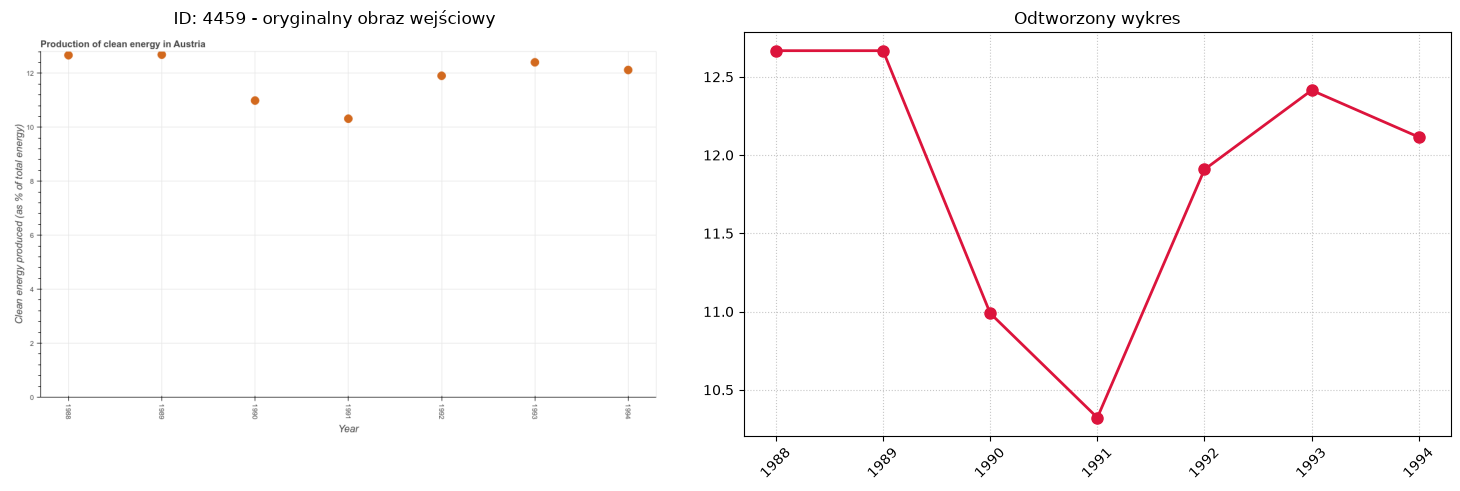

=== PRZYPADEK 2: NAJWIĘKSZY BŁĄD (ID: 4460) ===
Metryki: TP = 5, FP = 0, FN = 0
MAE Y = 0.1429%


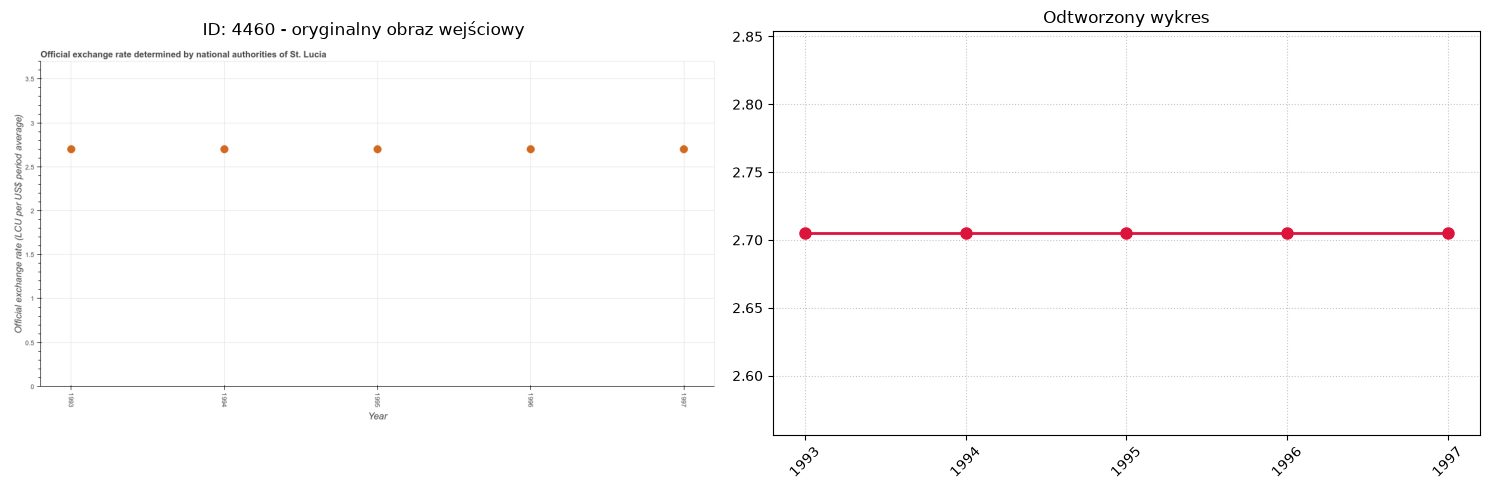

In [7]:
best_id = None
worst_id = None
min_error = float('inf')
max_error = -1.0

for res, t_id in zip(all_eval_results_test, test_ids):
    err = res["mae_y_pct"]
    if err is not None:
        if err > max_error:
            max_error = err
            worst_id = t_id
        if err < min_error and res["fp"] == 0 and res["fn"] == 0:
            min_error = err
            best_id = t_id

print(f"=== PRZYPADEK 1: SUKCES (ID: {best_id}) ===")
print(f"Metryki: F1 = 1.0, MAE Y = {min_error:.4f}%")
show_reconstruction(test_images[best_id], test_preds[best_id], title_prefix=f"ID: {best_id}")

if worst_id is not None and worst_id != best_id:
    print(f"=== PRZYPADEK 2: NAJWIĘKSZY BŁĄD (ID: {worst_id}) ===")
    worst_idx = test_ids.index(worst_id)
    w_res = all_eval_results_test[worst_idx]
    
    print(f"Metryki: TP = {w_res['tp']}, FP = {w_res['fp']}, FN = {w_res['fn']}")
    print(f"MAE Y = {w_res['mae_y_pct']:.4f}%")
    show_reconstruction(test_images[worst_id], test_preds[worst_id], title_prefix=f"ID: {worst_id}")
else:
    print("Brak błędnych przypadków do wyświetlenia - wszystkie wyniki są idealne!")

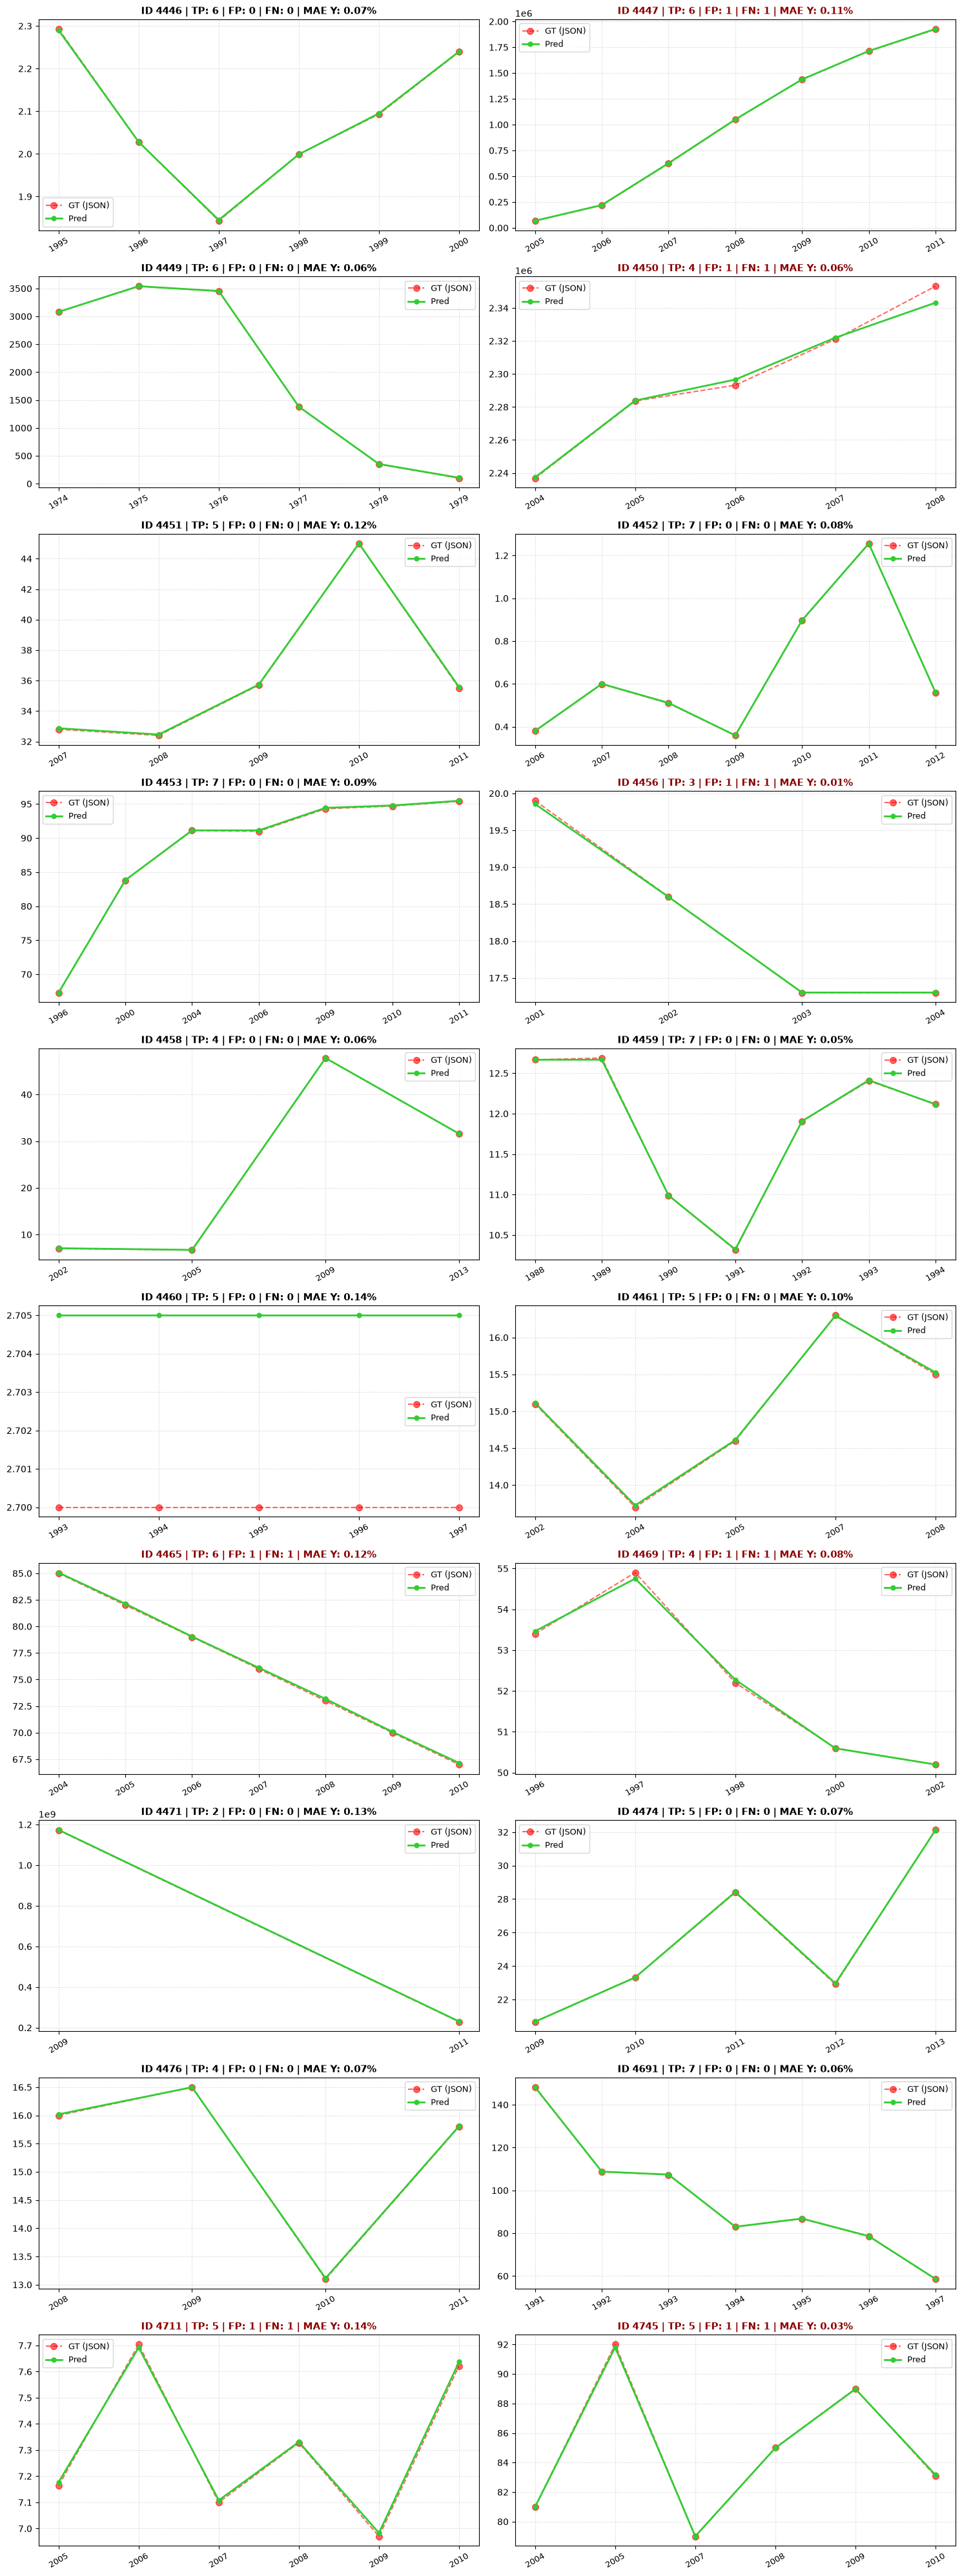

In [8]:
cols = 2
rows = math.ceil(len(test_ids) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(15, 4.0 * rows))

if len(test_ids) == 1:
    axes = [axes]
else:
    axes = axes.flatten()

results_dict = {t_id: res for t_id, res in zip(test_ids, all_eval_results_test)}

def sort_key(pt):
    x = pt["x"]
    return float(x) if str(x).replace('.', '', 1).isdigit() else str(x)

for idx, t_id in enumerate(test_ids):
    ax = axes[idx]

    preds = test_preds.get(t_id, [])
    gts = test_gts.get(t_id, [])

    preds_sorted = sorted(preds, key=sort_key)
    gts_sorted = sorted(gts, key=sort_key)

    pred_x = [str(pt["x"]) for pt in preds_sorted]
    pred_y = [pt["y"] for pt in preds_sorted]

    gt_x = [str(pt["x"]) for pt in gts_sorted]
    gt_y = [pt["y"] for pt in gts_sorted]

    ax.plot(
        gt_x, gt_y,
        "o--", color="red", label="GT (JSON)",
        markersize=7, linewidth=1.5, alpha=0.6
    )

    ax.plot(
        pred_x, pred_y,
        "o-", color="limegreen", label="Pred",
        markersize=5, linewidth=2
    )

    res = results_dict.get(t_id, {"tp": 0, "fp": 0, "fn": 0, "mae_y_pct": None})

    has_error = res["fn"] > 0 or res["fp"] > 0
    title_color = "darkred" if has_error else "black"
    
    mae_str = f"| MAE Y: {res['mae_y_pct']:.2f}%" if res['mae_y_pct'] is not None else ""

    ax.set_title(
        f"ID {t_id} | TP: {res['tp']} | FP: {res['fp']} | FN: {res['fn']} {mae_str}",
        fontsize=11, fontweight="bold", color=title_color
    )
    
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(fontsize=9, loc="best")
    ax.tick_params(axis="x", rotation=30, labelsize=9)

for j in range(len(test_ids), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout() 
plt.show()

Zapiszmy teraz uzyskane wyniki do pliku JSON za pomocą funkcji z converter.py

In [9]:
output_path = os.path.join("..", "data", "all_extracted_points.json")

export_to_json(test_preds, output_path)

print(f"zapisano wszystkie punkty dla {len(test_preds)} obrazów testowych do pliku JSON: {output_path}")

zapisano wszystkie punkty dla 20 obrazów testowych do pliku JSON: ../data/all_extracted_points.json


Jako, ze program działa prawie idealnie na tego typu wykresach, to teraz wygenerujemy sobie kilka wykresów, na których potencjalnie ten algorytm mógłby sobie przestać radzić, w celu zweryfikowania mozliwosci modulu wizyjnego

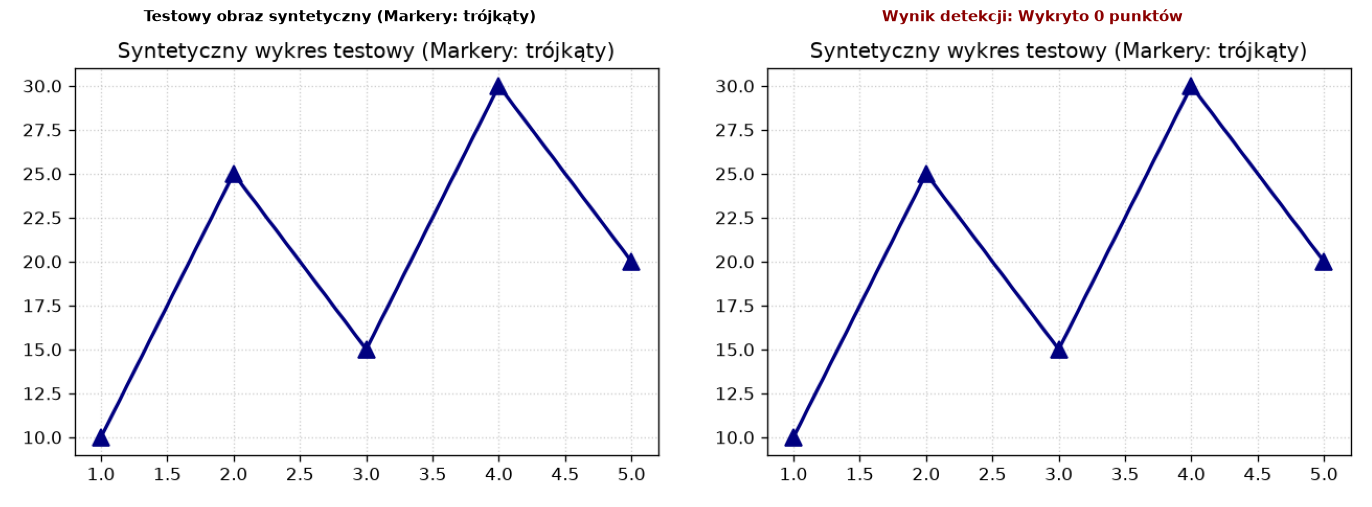

Oczekiwano: 5 punktów | Wykryto przez detector.py: 0 punktów.


In [10]:
fig, ax = plt.subplots(figsize=(6, 4), dpi=120)
x_synth = [1, 2, 3, 4, 5]
y_synth = [10, 25, 15, 30, 20]

ax.plot(x_synth, y_synth, marker='^', color='navy', linewidth=2, markersize=10)
ax.set_title("Syntetyczny wykres testowy (Markery: trójkąty)")
ax.grid(True, linestyle=":", alpha=0.6)

temp_file = "temp_synth.png"
plt.savefig(temp_file, bbox_inches='tight')
plt.close(fig)

img_bgr = cv2.imread(temp_file)
detected_pixels = detect_dots(img_bgr)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
axes[0].set_title("Testowy obraz syntetyczny (Markery: trójkąty)", fontsize=11, fontweight="bold")
axes[0].axis("off")

img_res = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
axes[1].imshow(img_res)

if detected_pixels:
    for pt in detected_pixels:
        axes[1].scatter(pt["x"], pt["y"], color="lime", s=100, edgecolors="black", zorder=5)
    axes[1].set_title(f"Wynik detekcji: Wykryto {len(detected_pixels)}/5 punktów", fontsize=11, fontweight="bold", color="darkred")
else:
    axes[1].set_title("Wynik detekcji: Wykryto 0 punktów", fontsize=11, fontweight="bold", color="darkred")
axes[1].axis("off")

plt.tight_layout()
plt.show()

if os.path.exists(temp_file):
    os.remove(temp_file)

print(f"Oczekiwano: 5 punktów | Wykryto przez detector.py: {len(detected_pixels)} punktów.")

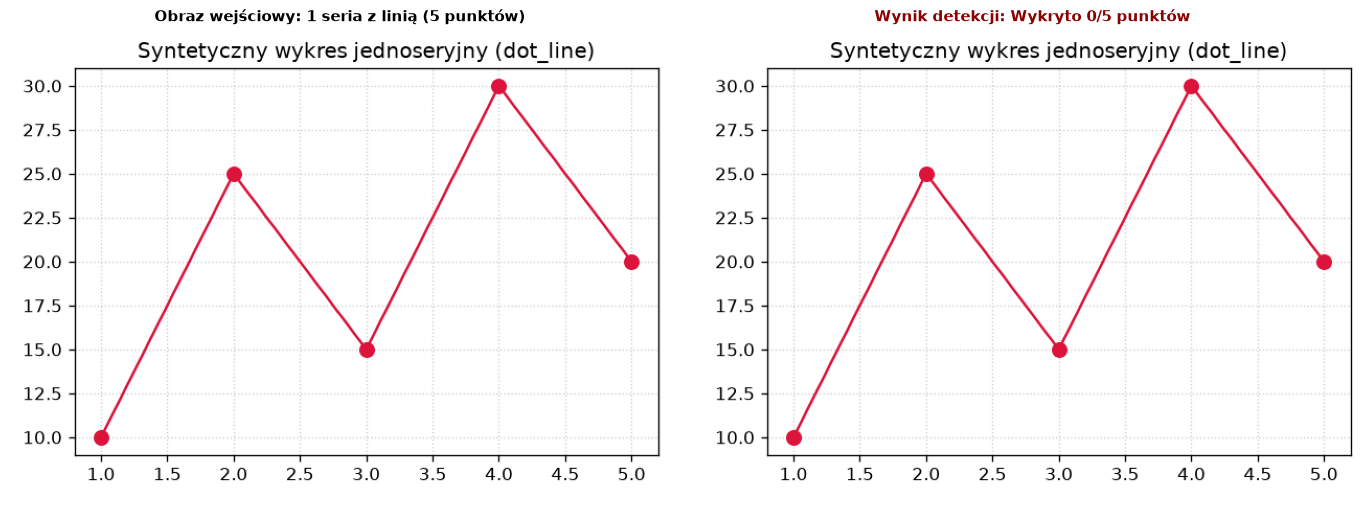

Oczekiwano: 5 punktów | Wykryto przez detector.py: 0 punktów.


In [11]:
fig, ax = plt.subplots(figsize=(6, 4), dpi=120)

x_vals = [1, 2, 3, 4, 5]
y_vals = [10, 25, 15, 30, 20]

ax.plot(x_vals, y_vals, marker='o', color='crimson', linewidth=1.5, markersize=8)

ax.set_title("Syntetyczny wykres jednoseryjny (dot_line)")
ax.grid(True, linestyle=":", alpha=0.6)

temp_file = "temp_dot_line.png"
plt.savefig(temp_file, bbox_inches='tight')
plt.close(fig)

img_bgr = cv2.imread(temp_file)

detected_pixels = detect_dots(img_bgr) 

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
axes[0].set_title("Obraz wejściowy: 1 seria z linią (5 punktów)", fontsize=11, fontweight="bold")
axes[0].axis("off")

img_res = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
axes[1].imshow(img_res)

if detected_pixels:
    for pt in detected_pixels:
        axes[1].scatter(pt["x"], pt["y"], color="lime", s=100, edgecolors="black", zorder=5)

n_found = len(detected_pixels) if detected_pixels else 0
status_color = "darkgreen" if n_found == 5 else "darkred"
axes[1].set_title(f"Wynik detekcji: Wykryto {n_found}/5 punktów", fontsize=11, fontweight="bold", color=status_color)
axes[1].axis("off")

plt.tight_layout()
plt.show()

if os.path.exists(temp_file):
    os.remove(temp_file)

print(f"Oczekiwano: 5 punktów | Wykryto przez detector.py: {n_found} punktów.")

## 5. Wnioski końcowe

### Gdzie program działa, a gdzie przestaje?
Analiza zbioru testowego wykazała wysoką skuteczność stworzonego pipeline'u. Klasyczne metody wizji komputerowej połączone z regresją liniową w zupełności wystarczają do bezbłędnej obsługi jednoseryjnych wykresów z wyraźnimi markerami i linowymi osiami.

1. **Główne źródło błędów:** Analiza przypadków z wykrytymi odchyleniami (np. ID 4460, w którym błąd MAE jest największy) wskazuje na to, ze te małe błędy $\text{MAE}_Y$ nie wynikają z problemów związanych z samą detekcją kropek. Głównym winowajcą jest sam sposób kalibracji osi, zaczerpnięty z adnotacji PlotQA. Do wyznaczenia funkcji skalującej uzylam srodków geometrycznych (y + h/2) bboxów, które zawierały etykiety tekstowe na osi. Środek pola tekstowego rzadko pokrywa się idealnie co do piksela z cienką linią podziałki na osi. Wprowadza to minimalne i systematyczne przesunięcia wyliczonej funkcji regresji. Przy wyjątkowo ostrym progu tolerancji to wlasnie ten ułamek piksela decyduje o sukcesie. 

2. **Gdzie rozwiązanie przestaje działać:**
   Przeprowadzone testy wykazały granice możliwości klasycznego przetwarzania obrazu:
   - **Obecność linii łączących w wykresach `dot_line`:** Jak pokazano na drugim teście syntetycznym, narysowanie ciągłej linii łączącej kropki powoduje fizyczne scalenie markerów z linią w jeden spójny kontur. Operacje morfologiczne i filtry geometrii odrzucają taki obiekt ze względu na drastyczny spadek kolistości, co skutkuje brakiem detekcji 
   - **Nietypowe kształty markerów (np. trójkąty):** pierwszy eksperyment pokazal wrażliwości filtrów na geometrię markerów. Zastosowanie trójkątnych wskaźników (`marker='^'`) sprawiło, że algorytm odrzucił wszystkie obiekty, ponieważ ich stosunek pola powierzchni do obwodu ($\text{circularity}$) spadł poniżej zdefiniowanego w kodzie progu $0.4$.
   - **Nieliniowe osie liczbowe:** Zastosowanie wielomianu pierwszego stopnia w `np.polyfit` ogranicza model wyłącznie do osi o skalowaniu liniowym. Dla skal np. logarytmicznych wyliczone wartości będą niepoprawne.

3. **Co zmieniłabym w kolejnym podejściu?:**
   - **Przejście na Deep Learning:** Zastąpienie filtrów wizyjnych OpenCV dedykowanym modelem detekcji obiektów. Wyeliminowałoby to konieczność ręcznego strojenia progu kolistości, problem odrzucania kanciastych markerów (np. trójkątów) oraz zlewających się linii czy nakładających się serii danych.
   - **Autonomiczna detekcja podziałek + OCR:** Wdrożenie modułu OCR (np. EasyOCR / Tesseract) połączonego z detekcją fizycznych kresek podziałki na osi (np. Transformacja Hougha). Wyeliminowałoby to systematyczny błąd przesunięcia wynikający ze środków ramek tekstowych (`bbox`) z pliku JSON i uniezależniłoby system od zewnętrznych adnotacji.
   - **Dynamiczne wykrywanie typu skalowania osi:** Rozbudowa modułu `converter.py` o automatyczne rozpoznawanie charakteru osi (liniowa vs logarytmiczna/eksponencjalna) i dobór odpowiedniego modelu regresji zamiast sztywnego dopasowywania wielomianu pierwszego stopnia (`np.polyfit`).